In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#modeling
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor,RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings


In [26]:
df=pd.read_csv('data/stud.csv')

In [27]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


# Preparing Independent(X) and Dependent(y) feature

In [28]:
X=df.drop(columns=['math_score'])
y=df['math_score']
y

0      72
1      69
2      90
3      47
4      76
       ..
995    88
996    62
997    59
998    68
999    77
Name: math_score, Length: 1000, dtype: int64

In [29]:
print("Categories in 'gender' variable:   ",end='')
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:   ",end="")
print(df['race_ethnicity'].unique())

print("Categories in 'parental_level_of_education' variable:   ",end="")
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:   ",end='')
print(df['lunch'].unique())

print("Categories in 'test_preparation_course' variable:   ",end='')
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:   <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:   <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental_level_of_education' variable:   <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:   <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test_preparation_course' variable:   <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [30]:
# Create column transformer for 3 types of transformers
num_features = X.select_dtypes(exclude='str').columns
cat_features = X.select_dtypes(include='str').columns

from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.compose import ColumnTransformer

oh_transformer = OneHotEncoder()
numeric_transformer = StandardScaler()

processor = ColumnTransformer(
    [
        ("OneHotEncoder:", oh_transformer, cat_features),
        ("StandardScaler:", numeric_transformer, num_features)
    ]
)

In [31]:
processor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OneHotEncoder:', ...), ('StandardScaler:', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name

In [32]:
X=processor.fit_transform(X)
X.shape

(1000, 19)

In [35]:
# Separate dataset into train test
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
X_train.shape, X_test.shape

((700, 19), (300, 19))

# Create an evaluation function to give all metrics after model training

In [40]:
def evaluate_model(true,pred):
    mse=mean_squared_error(true,pred)
    mae=mean_absolute_error(true,pred)
    rmse=np.sqrt(mse)
    r_square=r2_score(true,pred)
    return mae,rmse,r_square

In [53]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge" : Ridge(),
    "KNN" : KNeighborsRegressor(),
    "Support Vector Regressor" : SVR(),
    "Decision Tree" : DecisionTreeRegressor(),
    "AdaBoost" : AdaBoostRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Catboost" : CatBoostRegressor(verbose=False),
    "XGBoost" : XGBRegressor(),
    
}
model_list = []
r2_list = []

for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(X_train,y_train)  # Train Model

    # make prediction
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate train and test dataset
    model_train_mae, model_train_rmse, model_train_r_square = evaluate_model(y_train,y_train_pred)

    model_test_mae, model_test_rmse, model_test_r_square = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('Model Performance For Training Set')
    print("- Root Mean Square Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r_square))

    print('--------------------------------------------------')


    print('Model Performance For Testing Set')
    print("- Root Mean Square Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r_square))

    r2_list.append(model_test_r_square)


    print('='*35)
    print('\n')





Linear Regression
Model Performance For Training Set
- Root Mean Square Error: 5.2483
- Mean Absolute Error: 4.1985
- R2 Score: 0.8751
--------------------------------------------------
Model Performance For Testing Set
- Root Mean Square Error: 5.5576
- Mean Absolute Error: 4.4183
- R2 Score: 0.8759


Lasso
Model Performance For Training Set
- Root Mean Square Error: 6.5106
- Mean Absolute Error: 5.1582
- R2 Score: 0.8078
--------------------------------------------------
Model Performance For Testing Set
- Root Mean Square Error: 6.8705
- Mean Absolute Error: 5.3929
- R2 Score: 0.8103


Ridge
Model Performance For Training Set
- Root Mean Square Error: 5.2487
- Mean Absolute Error: 4.1977
- R2 Score: 0.8751
--------------------------------------------------
Model Performance For Testing Set
- Root Mean Square Error: 5.5566
- Mean Absolute Error: 4.4155
- R2 Score: 0.8759


KNN
Model Performance For Training Set
- Root Mean Square Error: 5.6790
- Mean Absolute Error: 4.5080
- R2 Score

# Results

In [58]:
pd.DataFrame(list(zip(model_list,r2_list)),columns=['Model Name', 'R2_Score']).sort_values(by=['R2_Score'],ascending=False)

,Model Name,R2_Score
2,Ridge,0.875907
0,Linear Regression,0.875863
8,Catboost,0.852108
7,Random Forest,0.847969
6,AdaBoost,0.838446
9,XGBoost,0.811816
1,Lasso,0.810281
3,KNN,0.772020
5,Decision Tree,0.727611
4,Support Vector Regressor,0.726848


# Linear Regression


In [61]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train,y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test,y_pred) * 100
print(f"Accuracy of The Model is {score:.2f}")

Accuracy of The Model is 87.59


# plot y_pred and y_test

Text(0, 0.5, 'Predicted')

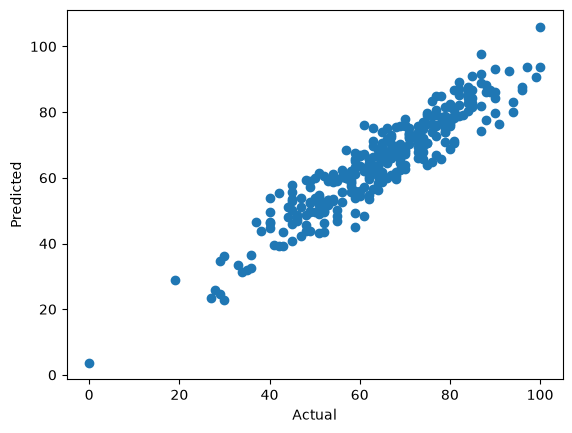

In [62]:
plt.scatter(y_test,y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")

<Axes: xlabel='math_score'>

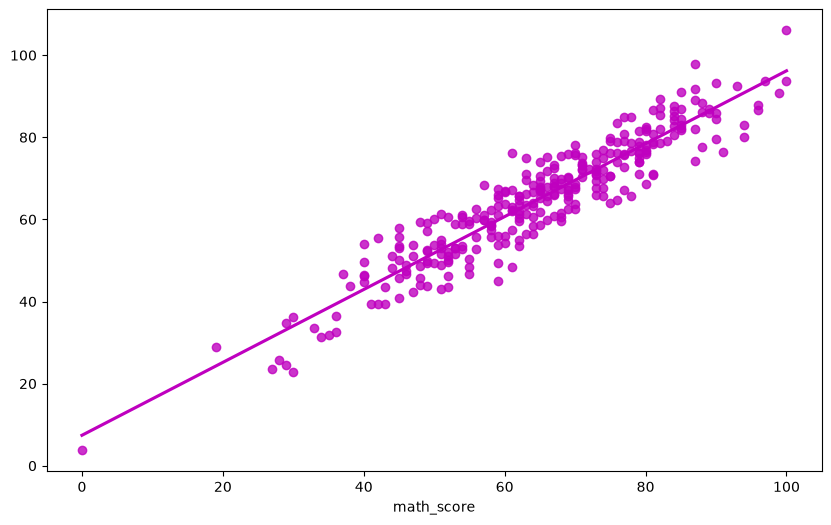

In [68]:
plt.figure(figsize=(10,6))
sns.regplot(x=y_test,y=y_pred,ci=None,color='m')

# Difference between Actual and Predicted Values

In [75]:
pred_df = pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred, 'Difference':y_test - y_pred})

In [76]:
pred_df

,Actual Value,Predicted Value,Difference
521,91,76.511652,14.488348
737,53,58.898180,-5.898180
740,80,76.938478,3.061522
660,74,76.965881,-2.965881
411,84,87.633152,-3.633152
...,...,...,...
468,77,72.854766,4.145234
935,70,62.606548,7.393452
428,65,58.650347,6.349653
7,40,44.841375,-4.841375
